First 5 records:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Species: ['setosa' 'versicolor' 'virginica']

Model Comparison:
               Model  Accuracy  Precision  Recall  F1 Score
Gaussian Naive Bayes    0.9667     0.9697  0.9667    0.9666
       Decision Tree    0.9333     0.9333  0.9333    0.9333


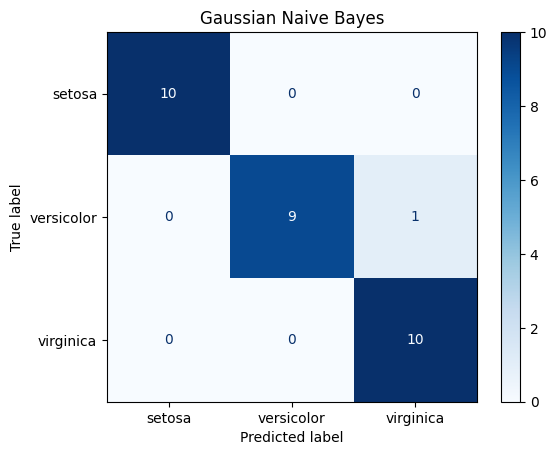

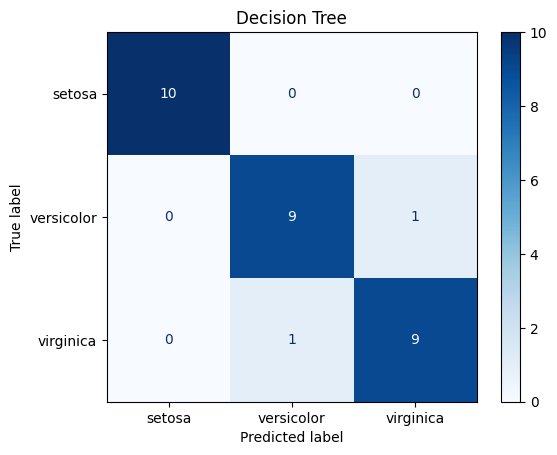


New Flower Prediction:
Gaussian Naive Bayes: setosa
Decision Tree: setosa


In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB  #Gaussian Naive Bayes Commonly used with continuous numerical features
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# 1. Load Iris dataset
data = load_iris()

X = pd.DataFrame(X_data := data.data, columns=data.feature_names)
y = data.target

print("First 5 records:")
print(X.head())

print("\nSpecies:", data.target_names)

# 2. Split dataset using the same split for both models
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#Gaussian Naive Bayes uses probability and assumes that each numerical feature follows a bell-shaped (normal) distribution within each class.

# 3. Train Gaussian Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

# 4. Train Decision Tree
dt_model = DecisionTreeClassifier(
    criterion="gini", random_state=42
)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

# 5. Evaluate both models
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(actual, predicted), 4),
        "Precision": round(precision_score(
            actual, predicted, average="macro", zero_division=0
        ), 4),
        "Recall": round(recall_score(
            actual, predicted, average="macro", zero_division=0
        ), 4),
        "F1 Score": round(f1_score(
            actual, predicted, average="macro", zero_division=0
        ), 4)
    }

results = pd.DataFrame([
    evaluate_model("Gaussian Naive Bayes", y_test, nb_pred),
    evaluate_model("Decision Tree", y_test, dt_pred)
])

print("\nModel Comparison:")
print(results.to_string(index=False))

# 6. Display confusion matrices
# Gaussian Naive Bayes
ConfusionMatrixDisplay.from_predictions(
    y_test, nb_pred, display_labels=data.target_names,
    cmap="Blues"
)
plt.title("Gaussian Naive Bayes")
plt.show()

# Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test, dt_pred, display_labels=data.target_names,
    cmap="Blues"
)
plt.title("Decision Tree")
plt.show()

# 7. Predict the species of a new flower
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=data.feature_names
)

nb_result = nb_model.predict(new_flower)[0]
dt_result = dt_model.predict(new_flower)[0]

print("\nNew Flower Prediction:")
print("Gaussian Naive Bayes:", data.target_names[nb_result])
print("Decision Tree:", data.target_names[dt_result])
